In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve, f1_score, classification_report
from sklearn.ensemble import IsolationForest
from xgboost import XGBClassifier

DATA_PATH = '/kaggle/input/datasets/cyberdeeplearning/veremi-extension-clean-data/mixalldata_clean.csv'
SEED = 42
WINDOW = 10                    # messages per window
RADII = [10, 50, 150, 300]     # neighbourhood radii (metres)
SEEN, SYBIL, UNKNOWN = list(range(0, 14)), [14, 15, 16], [17, 18, 19]

NAMES = ['Normal', 'ConstPos', 'ConstPosOffset', 'RandomPos', 'RandomPosOffset', 'ConstSpeed',
         'ConstSpeedOffset', 'RandomSpeed', 'RandomSpeedOffset', 'Disruptive', 'DataReplay',
         'DoS', 'DoSRandom', 'DoSDisruptive']

In [18]:
df = pd.read_csv(DATA_PATH)
df = df.drop(columns=[c for c in df.columns if df[c].nunique() <= 1])   
for c in df.select_dtypes('float64').columns.drop('sendTime'):
    df[c] = df[c].astype('float32')                                      

df = df.sort_values(['senderPseudo', 'sendTime']).reset_index(drop=True)
df['attack'] = (df['class'] != 0).astype(int)
df['sec'] = np.floor(df['sendTime']).astype(int)                         
df['n'] = df.groupby('senderPseudo').cumcount() + 1                    

print(df.shape)
print('messages per second:', df.groupby('sec').size().describe().round(0).to_dict())

(3194808, 24)
messages per second: {'count': 82671.0, 'mean': 39.0, 'std': 28.0, 'min': 1.0, '25%': 16.0, '50%': 33.0, '75%': 62.0, 'max': 123.0}


In [19]:
rng = np.random.default_rng(SEED)
cls_of = df.groupby('sender')['class'].first()                 
split = pd.Series('train', index=cls_of.index)

seen = cls_of[cls_of.isin(SEEN)].index
r = rng.random(len(seen))
split[seen[r > 0.70]] = 'val'
split[seen[r > 0.85]] = 'test'
split[cls_of[cls_of.isin(SYBIL)].index] = 'sybil'
split[cls_of[cls_of.isin(UNKNOWN)].index] = 'unknown'
df['split'] = df['sender'].map(split)

y, cls, sp_ = df['attack'].to_numpy(), df['class'].to_numpy(), df['split'].to_numpy()
m_train, m_val = sp_ == 'train', sp_ == 'val'
test_normal = (sp_ == 'test') & (cls == 0)
TESTS = {'seen attacks': sp_ == 'test',                          
         'unseen Sybil': (sp_ == 'sybil') | test_normal,         
         'unknown 17-19': (sp_ == 'unknown') | test_normal}
print(pd.Series(sp_).value_counts().to_dict())

{'train': 1778878, 'sybil': 431385, 'val': 388142, 'test': 383110, 'unknown': 213293}


In [20]:
g = df.groupby('senderPseudo')
dt = g['sendTime'].diff()
jump = np.hypot(g['posx'].diff(), g['posy'].diff())
spd = np.hypot(df.spdx, df.spdy)
hed = np.hypot(df.hedx, df.hedy)
acl = np.hypot(df.aclx, df.acly)
acl_along = (df.aclx * df.hedx + df.acly * df.hedy) / (hed + 1e-6)
dspd = spd.groupby(df['senderPseudo']).diff() / dt

F = pd.DataFrame({
    'dt': dt, 'jump': jump, 'spd': spd, 'acl': acl,
    'spd_gap': (jump / dt - spd).abs(),
    'acl_gap': (dspd - acl_along).abs(),
    'acl_excess': ((acl - 9) / 9).clip(lower=0),
    'hed_dev': (hed - 1).abs(),
    'spd_hed_cos': (df.spdx * df.hedx + df.spdy * df.hedy) / (spd * hed + 1e-6),
    'pos_noise': np.hypot(df.posx_n, df.posy_n),
    'spd_noise': np.hypot(df.spdx_n, df.spdy_n),
    'acl_noise': np.hypot(df.aclx_n, df.acly_n),
    'hed_noise': np.hypot(df.hedx_n, df.hedy_n),
    'flood': df.groupby(['senderPseudo', 'sec'])['sec'].transform('size'),
}).astype('float32')
PHYS = list(F.columns)
# Road prior: how many normal training cars were seen in this 10 m cell?
cell = np.floor(df.posx / 10).astype(int) * 100000 + np.floor(df.posy / 10).astype(int)
tr = m_train & (y == 0)
cars_per_cell = df[tr].groupby(cell[tr])['sender'].nunique()
road = cell.map(cars_per_cell).fillna(0)
road[tr] -= 1                                  
F['road_cars'] = road.astype('float32')
PHYS = list(F.columns)
print(F.shape)

(3194808, 15)


In [21]:
WCOLS = ['spd_gap', 'acl_gap', 'acl_excess', 'hed_dev', 'jump', 'dt', 'flood']

def window_features(n):
    roll = F[WCOLS].groupby(df['senderPseudo']).rolling(n, min_periods=1)
    out = []
    for name, part in [('mean', roll.mean()), ('max', roll.max())]:
        part = part.reset_index(level=0, drop=True).reindex(F.index)
        out.append(part.add_suffix(f'_{name}{n}'))
    return pd.concat(out, axis=1).astype('float32')

W = window_features(WINDOW)
print(W.shape)

(3194808, 14)


In [22]:
order = np.argsort(df['sec'].to_numpy(), kind='stable')      
S = df.iloc[order]
starts = np.r_[0, np.flatnonzero(np.diff(S['sec'].to_numpy())) + 1]
ends = np.r_[starts[1:], len(S)]                            

ps = S['senderPseudo'].to_numpy()
vx, vy = S['spdx'].to_numpy('float64'), S['spdy'].to_numpy('float64')
dtr = S['sec'].to_numpy() + 0.5 - S['sendTime'].to_numpy()    
px, py = S['posx'].to_numpy('float64') + vx * dtr, S['posy'].to_numpy('float64') + vy * dtr
spd_s = np.hypot(vx, vy)
hn = np.hypot(S.hedx, S.hedy).to_numpy('float64') + 1e-6
hx, hy = S.hedx.to_numpy('float64') / hn, S.hedy.to_numpy('float64') / hn
sg = F['pos_noise'].to_numpy()[order]

def dist(a, b):
    D = np.hypot(px[a:b, None] - px[None, a:b], py[a:b, None] - py[None, a:b])
    D[ps[a:b, None] == ps[None, a:b]] = np.inf                 
    return D

NB = ['nn_dist', 'nn_ratio', 'close5'] + [f'{k}_{R}' for R in RADII for k in ('cnt', 'spdz', 'hcos')]
out = np.zeros((len(S), len(NB)), dtype='float32')
for a, b in zip(starts, ends):
    D, idx = dist(a, b), np.arange(b - a)
    nn = D.argmin(1)
    nd = np.minimum(D[idx, nn], 999)
    s, v = sg[a:b], spd_s[a:b]
    row = [nd, np.minimum(nd / np.sqrt(s ** 2 + s[nn] ** 2 + 1e-6), 999), (D < 5).sum(1)]
    for R in RADII:
        M = (D < R).astype(float)
        cnt = M.sum(1)
        c = np.maximum(cnt, 1)
        m = M @ v / c
        var = M @ (v ** 2) / c - m ** 2
        mx, my = M @ hx[a:b] / c, M @ hy[a:b] / c
        z = np.where(cnt > 0, (v - m) / np.sqrt(np.maximum(var, 0) + 1), 0)
        cos = np.where(cnt > 0, (hx[a:b] * mx + hy[a:b] * my) / (np.hypot(mx, my) + 1e-6), 0)
        row += [cnt, z, cos]
    out[a:b] = np.column_stack(row)

NBF = pd.DataFrame(out, columns=NB, index=order).sort_index() 
X = pd.concat([F, W, NBF], axis=1)
print(X.shape)

(3194808, 44)


In [23]:
def metrics(yt, p, thr):
    tn, fp, fn, tp = confusion_matrix(yt, (p >= thr).astype(int), labels=[0, 1]).ravel()
    pr, rc = tp / (tp + fp + 1e-9), tp / (tp + fn + 1e-9)
    return dict(precision=pr, recall=rc, f1=2 * pr * rc / (pr + rc + 1e-9),
                fpr=fp / (fp + tn + 1e-9), auc=roc_auc_score(yt, p))

def best_thr(yt, p):
    grid = np.linspace(0.05, 0.95, 46)
    f1s = [f1_score(yt, p >= t) for t in grid]
    return grid[int(np.argmax(f1s))], max(f1s)

def vehicle_table(p, thr, mask):
    d = pd.DataFrame({'ps': df['senderPseudo'].to_numpy()[mask], 'y': y[mask], 'flag': p[mask] >= thr})
    return d.groupby('ps').agg(y=('y', 'max'), frac=('flag', 'mean'))

def latency(p, thr, mask):
    m = mask & (y == 1)
    d = pd.DataFrame({'ps': df['senderPseudo'].to_numpy()[m], 'n': df['n'].to_numpy()[m], 'flag': p[m] >= thr})
    first = d[d.flag].groupby('ps')['n'].min()
    return len(first) / d['ps'].nunique(), first.median()      

def make_xgb(**kw):
    return XGBClassifier(**{**dict(n_estimators=300, max_depth=8, learning_rate=0.1, subsample=0.8,
                                   colsample_bytree=0.8, tree_method='hist', device='cuda',
                                   random_state=SEED), **kw})

results, P = [], {}

def evaluate(p, name, thr):
    for tname, m in TESTS.items():
        r = metrics(y[m], p[m], thr); r.update(model=name, test=tname, level='message'); results.append(r)
        v = vehicle_table(p, thr, m)
        r = metrics(v['y'], v['frac'], 0.5); r.update(model=name, test=tname, level='vehicle'); results.append(r)

def run(cols, name):
    model = make_xgb().fit(X.loc[m_train, cols], y[m_train])
    p = model.predict_proba(X[cols])[:, 1]
    thr, _ = best_thr(y[m_val], p[m_val])
    evaluate(p, name, thr)
    P[name] = (p, thr)
    return model, p, thr

In [24]:
WIN = list(W.columns)
model_A, p_A, thr_A = run(PHYS, 'A: physics')
model_B, p_B, thr_B = run(PHYS + WIN, 'B: + window')
model_C, p_C, thr_C = run(PHYS + WIN + NB, 'C: + neighbourhood')

In [25]:
def neighbour_vote(p, R=150):
    q = p[order]
    res = q.copy()
    for a, b in zip(starts, ends):
        D = dist(a, b)
        W_ = np.where(D < R, 1 / (D + 5), 0.0)
        sw = W_.sum(1)
        res[a:b] = np.where(sw > 0, W_ @ q[a:b] / np.maximum(sw, 1e-12), q[a:b])
    out = np.empty_like(res)
    out[order] = res                                             
    return out

vote = neighbour_vote(p_C)
best = (-1, None, None, None)
for alpha in [1.0, 0.7, 0.5, 0.3]:
    q = alpha * p_C + (1 - alpha) * vote
    thr, f1 = best_thr(y[m_val], q[m_val])
    print(f'alpha={alpha}: val F1={f1:.4f}')
    if f1 > best[0]:
        best = (f1, alpha, thr, q)
_, ALPHA, thr_D, p_D = best
evaluate(p_D, 'D: + cooperative vote', thr_D)
P['D: + cooperative vote'] = (p_D, thr_D)
print('chosen alpha:', ALPHA)

alpha=1.0: val F1=0.9669
alpha=0.7: val F1=0.9659
alpha=0.5: val F1=0.9066
alpha=0.3: val F1=0.6902
chosen alpha: 1.0


In [26]:
cols = PHYS + WIN + NB
normal_train = np.flatnonzero(m_train & (y == 0))
normal_train = rng.choice(normal_train, min(500_000, len(normal_train)), replace=False)
iso = IsolationForest(n_estimators=200, random_state=SEED, n_jobs=-1).fit(X.iloc[normal_train][cols].fillna(0))

s = -iso.decision_function(X[cols].fillna(0))
s = (s - s.min()) / (s.max() - s.min())                         
thr_iso, _ = best_thr(y[m_val], s[m_val])
evaluate(s, 'E: Isolation Forest', thr_iso)
P['E: Isolation Forest'] = (s, thr_iso)

In [27]:
res = pd.DataFrame(results)[['model', 'test', 'level', 'precision', 'recall', 'f1', 'fpr', 'auc']].round(3)
print('VEHICLE LEVEL (majority vote over a pseudonym)')
print(res[res.level == 'vehicle'].drop(columns='level').to_string(index=False))
print('\nMESSAGE LEVEL')
print(res[res.level == 'message'].drop(columns='level').to_string(index=False))
res.to_csv('results_table.csv', index=False)

VEHICLE LEVEL (majority vote over a pseudonym)
                model          test  precision  recall    f1   fpr   auc
           A: physics  seen attacks      1.000   0.933 0.965 0.000 0.995
           A: physics  unseen Sybil      1.000   0.756 0.861 0.000 0.959
           A: physics unknown 17-19      1.000   0.928 0.963 0.000 0.976
          B: + window  seen attacks      1.000   0.950 0.975 0.000 0.995
          B: + window  unseen Sybil      1.000   0.816 0.898 0.000 0.934
          B: + window unknown 17-19      1.000   0.939 0.969 0.000 0.982
   C: + neighbourhood  seen attacks      1.000   0.950 0.975 0.000 0.995
   C: + neighbourhood  unseen Sybil      1.000   0.815 0.898 0.000 0.931
   C: + neighbourhood unknown 17-19      1.000   0.903 0.949 0.000 0.963
D: + cooperative vote  seen attacks      1.000   0.950 0.975 0.000 0.995
D: + cooperative vote  unseen Sybil      1.000   0.815 0.898 0.000 0.931
D: + cooperative vote unknown 17-19      1.000   0.903 0.949 0.000 0.963
  E:

In [28]:
p, thr = P['D: + cooperative vote']
for tname, m in TESTS.items():
    det, lat = latency(p, thr, m)
    print(f'{tname:14s} attackers detected: {det:.1%} | median messages until first flag: {lat}')

rows = []
for k in SYBIL + UNKNOWN:
    v = vehicle_table(p, thr, cls == k)
    rows.append(dict(cls=k, pseudonyms=len(v), share_flagged=(v['frac'] >= 0.5).mean()))
v = vehicle_table(p, thr, test_normal)
rows.append(dict(cls='normal (this is the FPR)', pseudonyms=len(v), share_flagged=(v['frac'] >= 0.5).mean()))
print(pd.DataFrame(rows).round(3).to_string(index=False))

seen attacks   attackers detected: 98.9% | median messages until first flag: 1.0
unseen Sybil   attackers detected: 86.5% | median messages until first flag: 1.0
unknown 17-19  attackers detected: 92.8% | median messages until first flag: 1.0
                     cls  pseudonyms  share_flagged
                      14         389          1.000
                      15         389          1.000
                      16        1564          0.723
                      17       22259          0.761
                      18       36106          1.000
                      19       35874          0.893
normal (this is the FPR)        2592          0.000


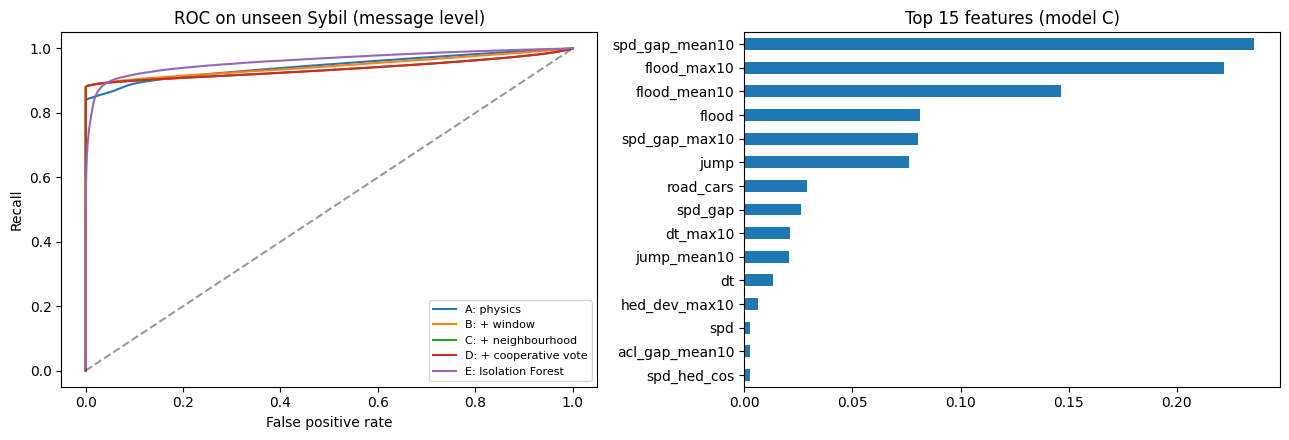

In [29]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
m = TESTS['unseen Sybil']
for name, (p_, _) in P.items():
    fpr, tpr, _ = roc_curve(y[m], p_[m])
    ax[0].plot(fpr, tpr, label=name)
ax[0].plot([0, 1], [0, 1], 'k--', alpha=0.4)
ax[0].set(xlabel='False positive rate', ylabel='Recall', title='ROC on unseen Sybil (message level)')
ax[0].legend(fontsize=8)

imp = pd.Series(model_C.feature_importances_, index=PHYS + WIN + NB).sort_values().tail(15)
imp.plot(kind='barh', ax=ax[1], title='Top 15 features (model C)')
plt.tight_layout(); plt.show()

In [30]:
rows = []
for n in [5, 10, 20]:
    Xn = pd.concat([F, window_features(n), NBF], axis=1)
    mdl = make_xgb().fit(Xn[m_train], y[m_train])
    p = mdl.predict_proba(Xn)[:, 1]
    thr, _ = best_thr(y[m_val], p[m_val])
    for tname in ['seen attacks', 'unseen Sybil']:
        v = vehicle_table(p, thr, TESTS[tname])
        det, lat = latency(p, thr, TESTS[tname])
        rows.append(dict(window=n, test=tname, f1=metrics(v['y'], v['frac'], 0.5)['f1'],
                         detected=det, median_latency=lat))
tradeoff = pd.DataFrame(rows).round(3)
print(tradeoff.to_string(index=False))

 window         test    f1  detected  median_latency
      5 seen attacks 0.972     0.989             1.0
      5 unseen Sybil 0.887     0.870             1.0
     10 seen attacks 0.975     0.989             1.0
     10 unseen Sybil 0.898     0.865             1.0
     20 seen attacks 0.979     0.989             1.0
     20 unseen Sybil 0.905     0.869             1.0


In [31]:
mc = XGBClassifier(n_estimators=150, max_depth=6, learning_rate=0.15, subsample=0.8, colsample_bytree=0.8,
                   tree_method='hist', device='cuda', objective='multi:softprob', random_state=SEED)
mc.fit(X.loc[m_train], cls[m_train])
mt = TESTS['seen attacks']
print(classification_report(cls[mt], mc.predict(X[mt]), labels=SEEN, target_names=NAMES, digits=3, zero_division=0))

                   precision    recall  f1-score   support

           Normal      0.980     0.998     0.989    285233
         ConstPos      0.996     0.994     0.995      8254
   ConstPosOffset      0.988     0.799     0.884      7161
        RandomPos      0.990     0.994     0.992      5451
  RandomPosOffset      0.989     0.991     0.990      4676
       ConstSpeed      0.948     0.910     0.928      5702
 ConstSpeedOffset      0.901     0.947     0.923      6376
      RandomSpeed      0.995     0.993     0.994      6614
RandomSpeedOffset      0.985     0.976     0.981      6675
       Disruptive      0.998     0.824     0.902      6268
       DataReplay      0.756     0.843     0.797      5620
              DoS      0.884     0.776     0.826      8011
        DoSRandom      0.910     0.581     0.709      6887
    DoSDisruptive      1.000     0.999     1.000     20182

         accuracy                          0.975    383110
        macro avg      0.951     0.902     0.922    38

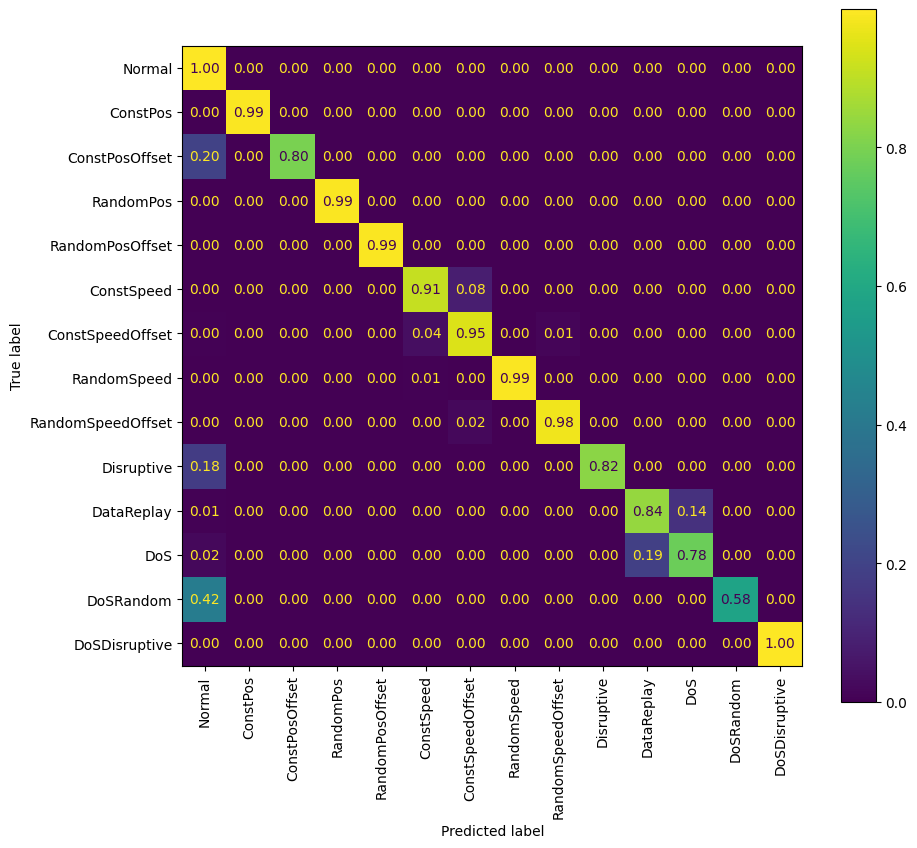

In [32]:
from sklearn.metrics import ConfusionMatrixDisplay
fig, ax = plt.subplots(figsize=(10, 9))
ConfusionMatrixDisplay.from_predictions(cls[mt], mc.predict(X[mt]), labels=SEEN, display_labels=NAMES,
                                        normalize='true', values_format='.2f', xticks_rotation=90, ax=ax)
plt.show()